In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [30]:
# Import feature engineered data
df = pd.read_csv(r"C:\Users\HP\OneDrive\Documents\AMDARI\FINLORA PROJECT\DATA\CLEAN\cleaned_finlora_data.csv")

In [31]:
df.describe()

,personal_spend_baseline_usd,day_of_week,hour_of_day,amount,amount_to_avg_ratio,avg_transaction_amount_30d,transaction_velocity_1h,is_cross_border,is_new_device,is_fraud,...,hour_cos,dow_sin,dow_cos,rate_to_usd,amount_usd,avg_transaction_amount_30d_usd,amount_vs_personal_baseline,amount_deviation_30d_usd,new_device_amount_anomaly,account_age_days
count,126000.000000,126000.000000,126000.000000,1.260000e+05,126000.000000,1.260000e+05,126000.000000,126000.000000,126000.000000,126000.000000,...,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000
mean,292.277286,3.016540,13.542111,7.966235e+05,7.921400,7.676637e+05,0.011429,0.020198,0.030913,0.026603,...,-0.285933,-0.005871,0.003495,0.562762,1094.204081,1167.218627,2.382768,-73.014546,0.237861,354.721992
std,631.504181,2.006247,5.260369,4.054351e+06,153.566706,3.290356e+06,0.110323,0.140679,0.173082,0.160921,...,0.608186,0.708902,0.705280,0.581247,4511.626342,3499.380210,3.942715,4094.325991,16.288476,331.327033
min,3.770000,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,-1.000000,-0.974928,-0.900969,0.000610,0.000000,0.000000,0.000000,-134344.210938,0.000000,0.000000
25%,44.510000,1.000000,9.000000,6.310500e+01,0.250000,9.242750e+01,0.000000,0.000000,0.000000,0.000000,...,-0.866025,-0.781831,-0.900969,0.000690,20.303220,28.740000,0.336148,-113.358355,0.000000,35.000000
50%,92.190000,3.000000,14.000000,5.942240e+03,0.980000,5.942240e+03,0.000000,0.000000,0.000000,0.000000,...,-0.500000,0.000000,-0.222521,0.000740,73.789277,101.040150,0.766933,-0.810000,0.000000,289.000000
75%,296.230000,5.000000,18.000000,1.208470e+05,1.830000,1.575701e+05,0.000000,0.000000,0.000000,0.000000,...,0.258819,0.781831,0.623490,1.151400,442.712662,732.009048,2.339176,35.941814,0.000000,577.000000
max,10469.650000,6.000000,23.000000,2.691614e+08,31762.690000,1.733621e+08,3.000000,1.000000,1.000000,1.000000,...,1.000000,0.974928,1.000000,1.381000,298224.151200,138394.295438,73.206867,279836.639820,3107.800000,1682.000000


#### Pre-processing before modelling

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126000 entries, 0 to 125999
Data columns (total 38 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   account_created_date            126000 non-null  object 
 1   personal_spend_baseline_usd     126000 non-null  float64
 2   account_type_y                  126000 non-null  object 
 3   kyc_tier_y                      126000 non-null  object 
 4   timestamp                       126000 non-null  object 
 5   day_of_week                     126000 non-null  int64  
 6   hour_of_day                     126000 non-null  int64  
 7   description                     126000 non-null  object 
 8   merchant_name                   126000 non-null  object 
 9   merchant_category               126000 non-null  object 
 10  channel                         126000 non-null  object 
 11  amount                          126000 non-null  float64
 12  currency_y      

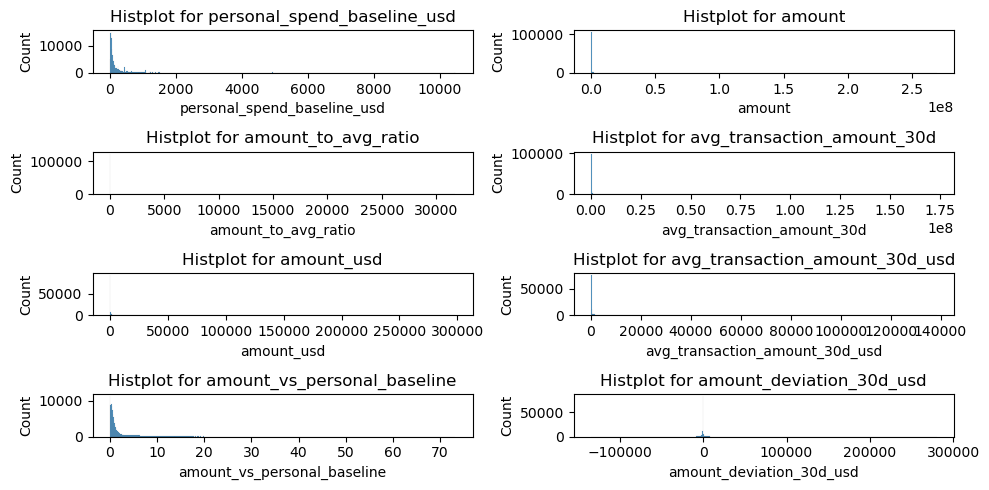

In [33]:
# Visualization of extreme values and outliers

num_columns = ['personal_spend_baseline_usd','amount','amount_to_avg_ratio','avg_transaction_amount_30d',
               'amount_usd','avg_transaction_amount_30d_usd','amount_vs_personal_baseline','amount_deviation_30d_usd']

fig, ax = plt.subplots(nrows=4, ncols=2, figsize=(10, 5))
ax=ax.flatten()
for idx, col in enumerate(num_columns):
    sns.histplot(df[col], ax=ax[idx])
    ax[idx].set_title(f"Histplot for {col}")
plt.tight_layout()
plt.show()

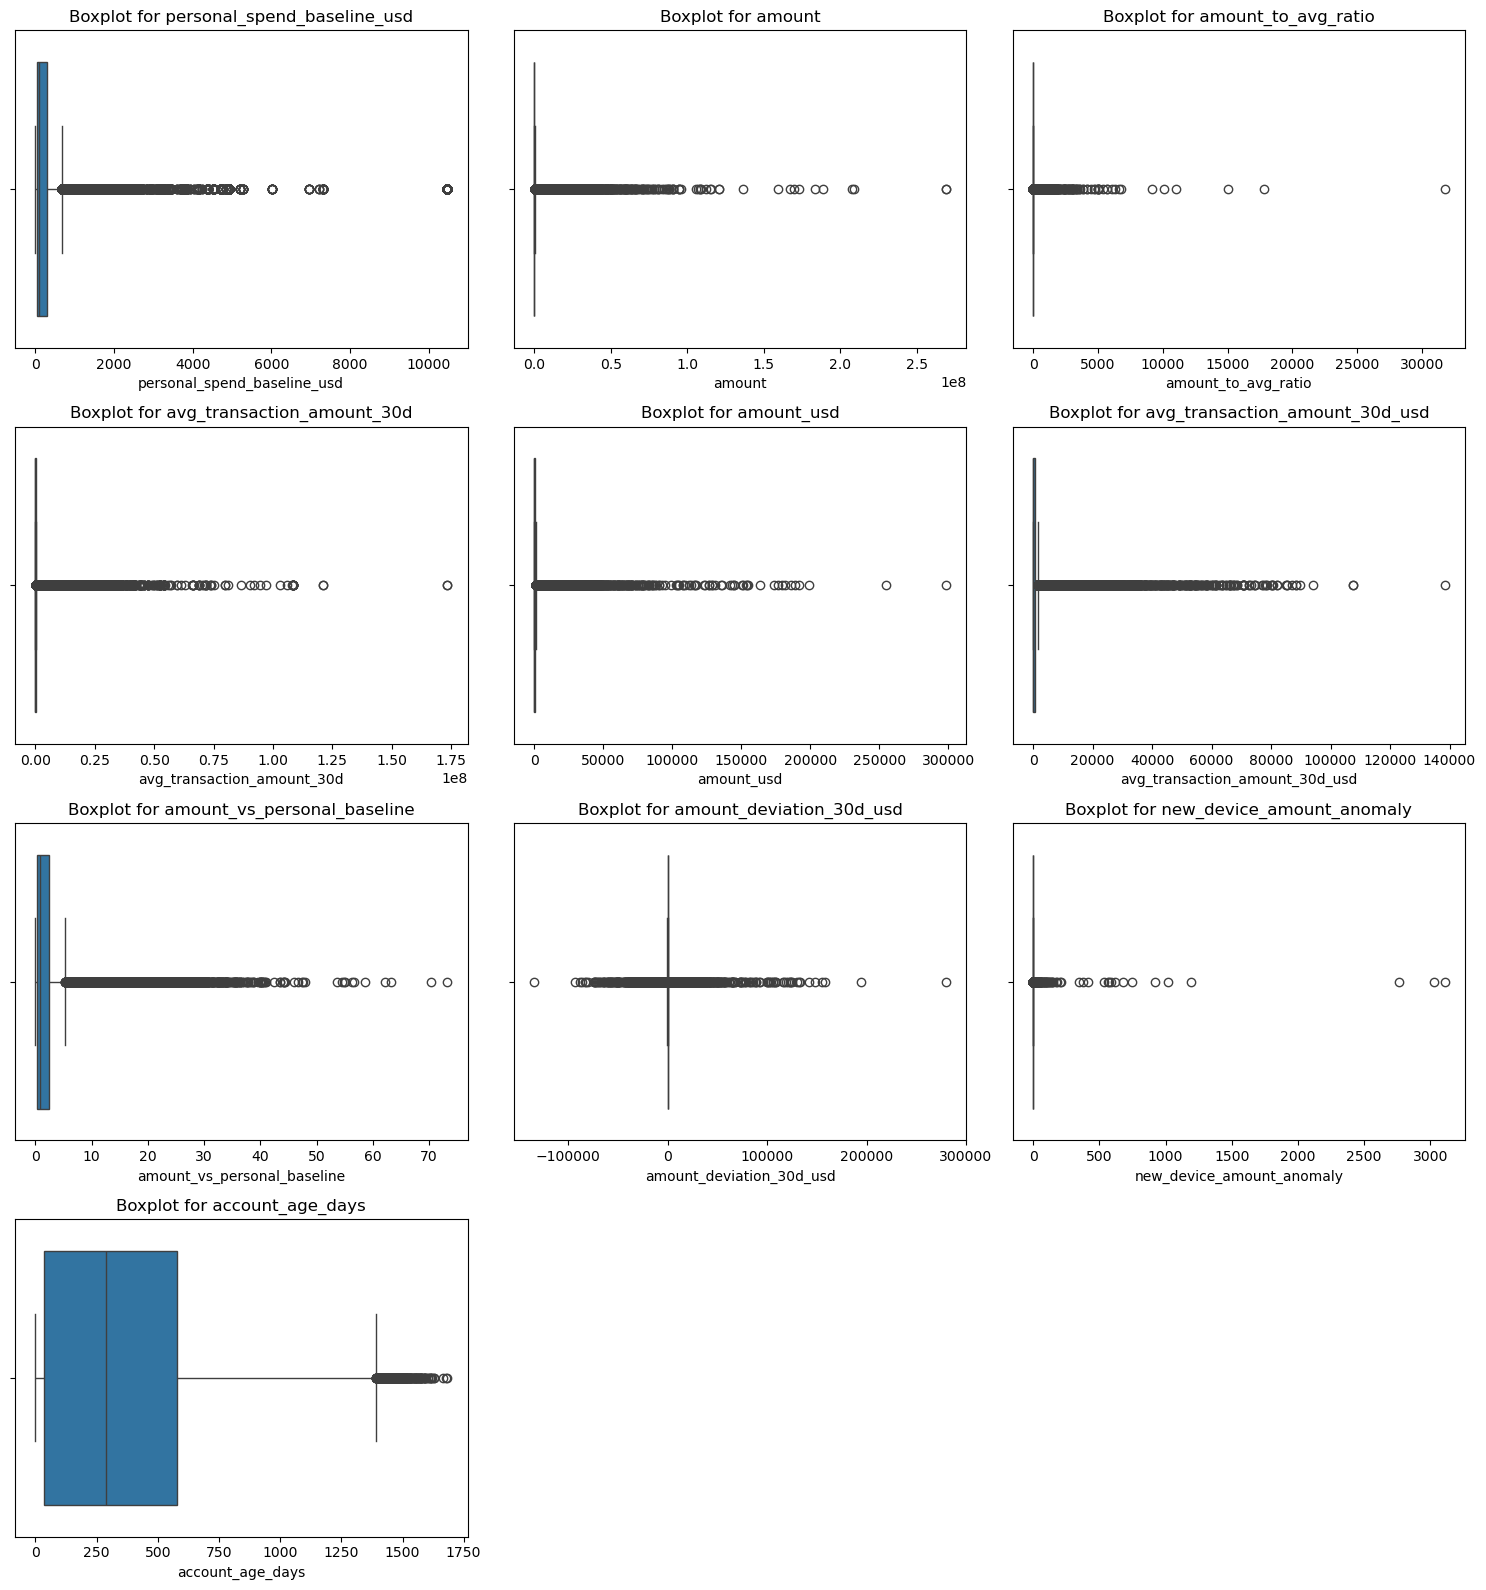

In [34]:
# Select only numeric columns from your dataframe
num_columns = ['personal_spend_baseline_usd','amount','amount_to_avg_ratio','avg_transaction_amount_30d',
               'amount_usd','avg_transaction_amount_30d_usd','amount_vs_personal_baseline',
               'amount_deviation_30d_usd','new_device_amount_anomaly','account_age_days']


# Define subplot grid size dynamically
n_cols = 3   # number of plots per row
n_rows = (len(num_columns) + n_cols - 1) // n_cols  # enough rows to fit all

fig, ax = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(15, n_rows*4))
ax = ax.flatten()

for idx, col in enumerate(num_columns):
    sns.boxplot(x= df[col], ax=ax[idx])   # boxplot is best for outliers
    ax[idx].set_title(f"Boxplot for {col}")

# Remove any unused subplots
for j in range(idx+1, len(ax)):
    fig.delaxes(ax[j])

plt.tight_layout()
plt.show()


#### Box plot shows presence of extreme values and outliers in the data

In [35]:
# Handling extreme values and outliers by log transformation

# Select numeric columns
num_columns = [
    'personal_spend_baseline_usd','amount','amount_to_avg_ratio','avg_transaction_amount_30d',
    'amount_usd','avg_transaction_amount_30d_usd','amount_vs_personal_baseline',
    'amount_deviation_30d_usd','new_device_amount_anomaly','account_age_days'
]

# Apply signed log transformation
df_log = df.copy()
for col in num_columns:
    x = df[col]
    df_log[col] = np.sign(x) * np.log1p(np.abs(x))


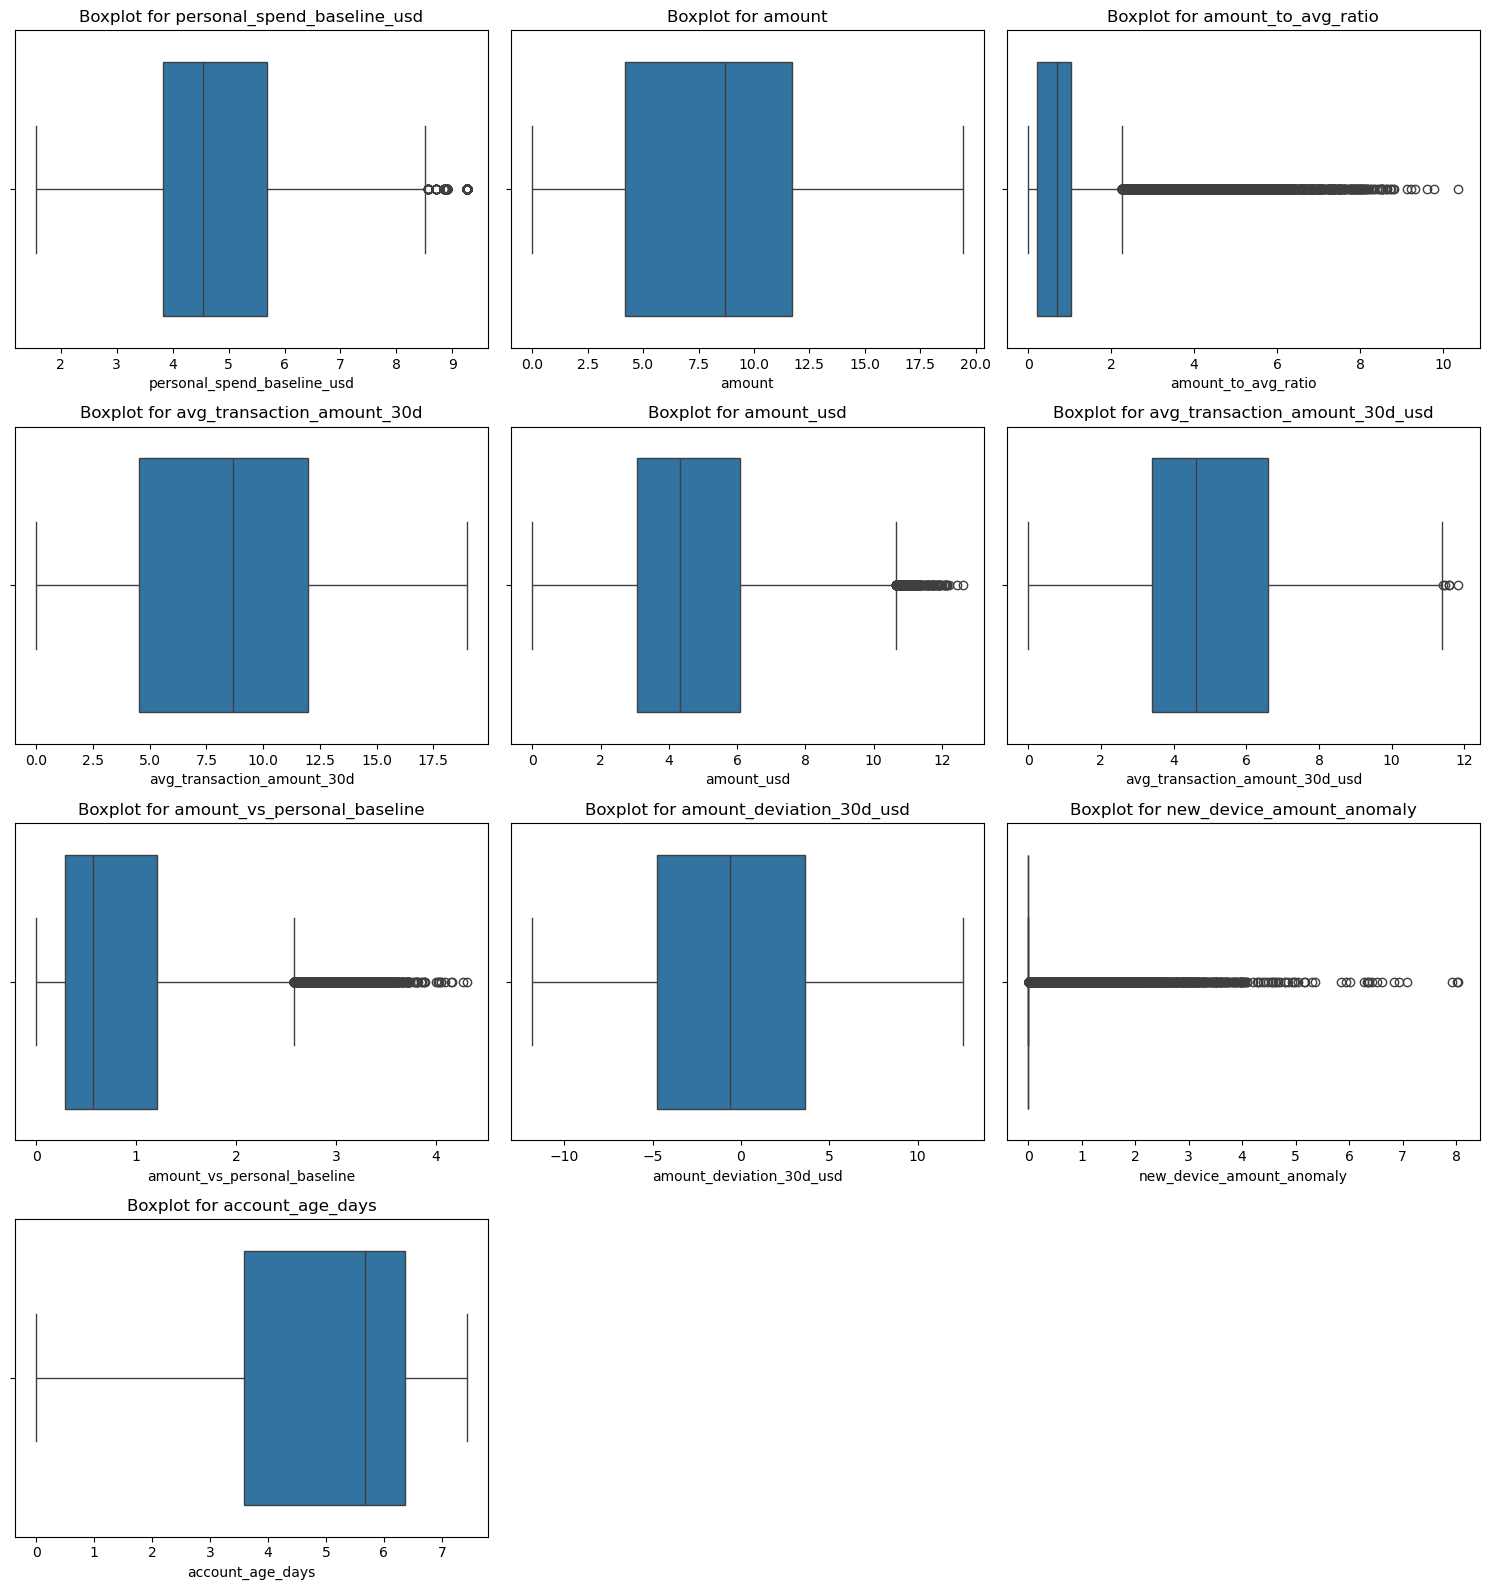

In [36]:
# Select only numeric columns from your dataframe

num_columns = ['personal_spend_baseline_usd','amount','amount_to_avg_ratio','avg_transaction_amount_30d',
               'amount_usd','avg_transaction_amount_30d_usd','amount_vs_personal_baseline',
               'amount_deviation_30d_usd','new_device_amount_anomaly','account_age_days']


# Define subplot grid size dynamically
n_cols = 3   # number of plots per row
n_rows = (len(num_columns) + n_cols - 1) // n_cols 

fig, ax = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(15, n_rows*4))
ax = ax.flatten()

for idx, col in enumerate(num_columns):
    sns.boxplot(x= df_log[col], ax=ax[idx])  
    ax[idx].set_title(f"Boxplot for {col}")

# Remove any unused subplots
for j in range(idx+1, len(ax)):
    fig.delaxes(ax[j])

plt.tight_layout()
plt.show()


###### post log transformation subplot shows compression of extreme values but some outliers are still visible

In [37]:
df_log.head(1)

,account_created_date,personal_spend_baseline_usd,account_type_y,kyc_tier_y,timestamp,day_of_week,hour_of_day,description,merchant_name,merchant_category,...,dow_cos,fx_date,currency,rate_to_usd,amount_usd,avg_transaction_amount_30d_usd,amount_vs_personal_baseline,amount_deviation_30d_usd,new_device_amount_anomaly,account_age_days
0,2024-02-16,6.82974,Business,Tier2_Verified,2025-02-01 11:34:00,5,11,INTL WIRE - INTERNATIONAL WIRE REF341401,International Wire,Wire Transfer,...,-0.222521,2025-02-01,USD,1.0,8.381053,8.381053,1.744263,0.0,0.0,5.863631


In [38]:
df_log.describe()

,personal_spend_baseline_usd,day_of_week,hour_of_day,amount,amount_to_avg_ratio,avg_transaction_amount_30d,transaction_velocity_1h,is_cross_border,is_new_device,is_fraud,...,hour_cos,dow_sin,dow_cos,rate_to_usd,amount_usd,avg_transaction_amount_30d_usd,amount_vs_personal_baseline,amount_deviation_30d_usd,new_device_amount_anomaly,account_age_days
count,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,...,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000,126000.000000
mean,4.778837,3.016540,13.542111,8.264364,0.835323,8.595450,0.011429,0.020198,0.030913,0.026603,...,-0.285933,-0.005871,0.003495,0.562762,4.647010,4.970902,0.847713,-0.710045,0.025631,4.513498
std,1.267881,2.006247,5.260369,4.331557,0.909845,4.221701,0.110323,0.140679,0.173082,0.160921,...,0.608186,0.708902,0.705280,0.581247,2.152479,2.122762,0.761490,5.040974,0.215026,2.547289
min,1.562346,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,-1.000000,-0.974928,-0.900969,0.000610,0.000000,0.000000,0.000000,-11.808168,0.000000,0.000000
25%,3.817932,1.000000,9.000000,4.160522,0.223144,4.537186,0.000000,0.000000,0.000000,0.000000,...,-0.866025,-0.781831,-0.900969,0.000690,3.058858,3.392493,0.289791,-4.739337,0.000000,3.583519
50%,4.534640,3.000000,14.000000,8.690010,0.683097,8.690010,0.000000,0.000000,0.000000,0.000000,...,-0.500000,0.000000,-0.222521,0.000740,4.314675,4.625366,0.569245,-0.593327,0.000000,5.669881
75%,5.694506,5.000000,18.000000,11.702289,1.040277,11.967632,0.000000,0.000000,0.000000,0.000000,...,0.258819,0.781831,0.623490,1.151400,6.095177,6.597158,1.205724,3.609344,0.000000,6.359574
max,9.256331,6.000000,23.000000,19.410822,10.366079,18.970893,3.000000,1.000000,1.000000,1.000000,...,1.000000,0.974928,1.000000,1.381000,12.605604,11.837869,4.306857,12.541965,8.041992,7.428333


In [39]:
df_log.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126000 entries, 0 to 125999
Data columns (total 38 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   account_created_date            126000 non-null  object 
 1   personal_spend_baseline_usd     126000 non-null  float64
 2   account_type_y                  126000 non-null  object 
 3   kyc_tier_y                      126000 non-null  object 
 4   timestamp                       126000 non-null  object 
 5   day_of_week                     126000 non-null  int64  
 6   hour_of_day                     126000 non-null  int64  
 7   description                     126000 non-null  object 
 8   merchant_name                   126000 non-null  object 
 9   merchant_category               126000 non-null  object 
 10  channel                         126000 non-null  object 
 11  amount                          126000 non-null  float64
 12  currency_y      

##### Dropping Redundant Columns

In [41]:
cols_to_drop = [
    "timestamp",                     # redundant with derived time features
    "fx_date",                       # FX reference date, usually not needed
    "currency",                      # duplicate of currency_y
    "amount",                        # drop raw amount, keep amount_usd
    "avg_transaction_amount_30d",    # drop raw, keep USD-normalized version
    "hour",                          # drop raw, keep hour_sin/hour_cos
    "hour_of_day",                   # duplicate of hour
    "day_of_week",                   # redundant with dow_sin/dow_cos
    "account_created_date",          # can be replaced with account_age_days
    "description",                   # often unstructured text, low signal
    "merchant_name",                  # too granular, category is stronger
    "status"
]

df_log = df_log.drop(columns=cols_to_drop)


In [42]:
df_log.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126000 entries, 0 to 125999
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   personal_spend_baseline_usd     126000 non-null  float64
 1   account_type_y                  126000 non-null  object 
 2   kyc_tier_y                      126000 non-null  object 
 3   merchant_category               126000 non-null  object 
 4   channel                         126000 non-null  object 
 5   currency_y                      126000 non-null  object 
 6   amount_to_avg_ratio             126000 non-null  float64
 7   transaction_velocity_1h         126000 non-null  int64  
 8   transaction_country             126000 non-null  object 
 9   home_country_y                  126000 non-null  object 
 10  is_cross_border                 126000 non-null  int64  
 11  is_new_device                   126000 non-null  float64
 12  is_fraud        

#### VFI Analysis

In [44]:
# Train and test split for vfi analysis

# Features and target
v_x = df_log.drop(columns=['is_fraud'])
v_y = df_log['is_fraud']


In [45]:
from sklearn.model_selection import train_test_split

# Train/test split
v_x_train, v_x_test, v_y_train, v_y_test = train_test_split(v_x, v_y, test_size=0.2, random_state=42)


In [46]:
# Checking VIF 
from statsmodels.stats.outliers_influence import variance_inflation_factor

v_x = v_x_train.select_dtypes(include=[np.number])
v_x = v_x.replace([np.inf, -np.inf], np.nan).dropna()

# Create DataFrame for VIF
vif_data = pd.DataFrame()
vif_data["Feature"] = v_x.columns
vif_data["VIF"] = [variance_inflation_factor(v_x.values, i) for i in range(v_x.shape[1])]

#print(vif_data.sort_values(by="VIF", ascending=False))
vif_data.sort_values(by="VIF", ascending=False)

,Feature,VIF
0,personal_spend_baseline_usd,156.293886
12,amount_usd,114.349497
13,avg_transaction_amount_30d_usd,78.512898
5,year,35.225259
14,amount_vs_personal_baseline,27.814548
1,amount_to_avg_ratio,8.889141
6,month,4.711305
17,account_age_days,4.153879
15,amount_deviation_30d_usd,4.043143
11,rate_to_usd,1.953996


#### Severe multicollinearity

- personal_spend_baseline_usd (156.29), amount_usd (114.35), and avg_transaction_amount_30d_usd (78.51) show extremely high VIF values.

- These features are highly correlated with each other, suggesting redundancy. Keeping all of them risks unstable regression coefficients.

#### Moderate multicollinearity

- year (35.22) and amount_vs_personal_baseline (27.81) also exceed the typical threshold (VIF > 10).

- They may overlap conceptually with the high-VIF features above, contributing to inflated variance.

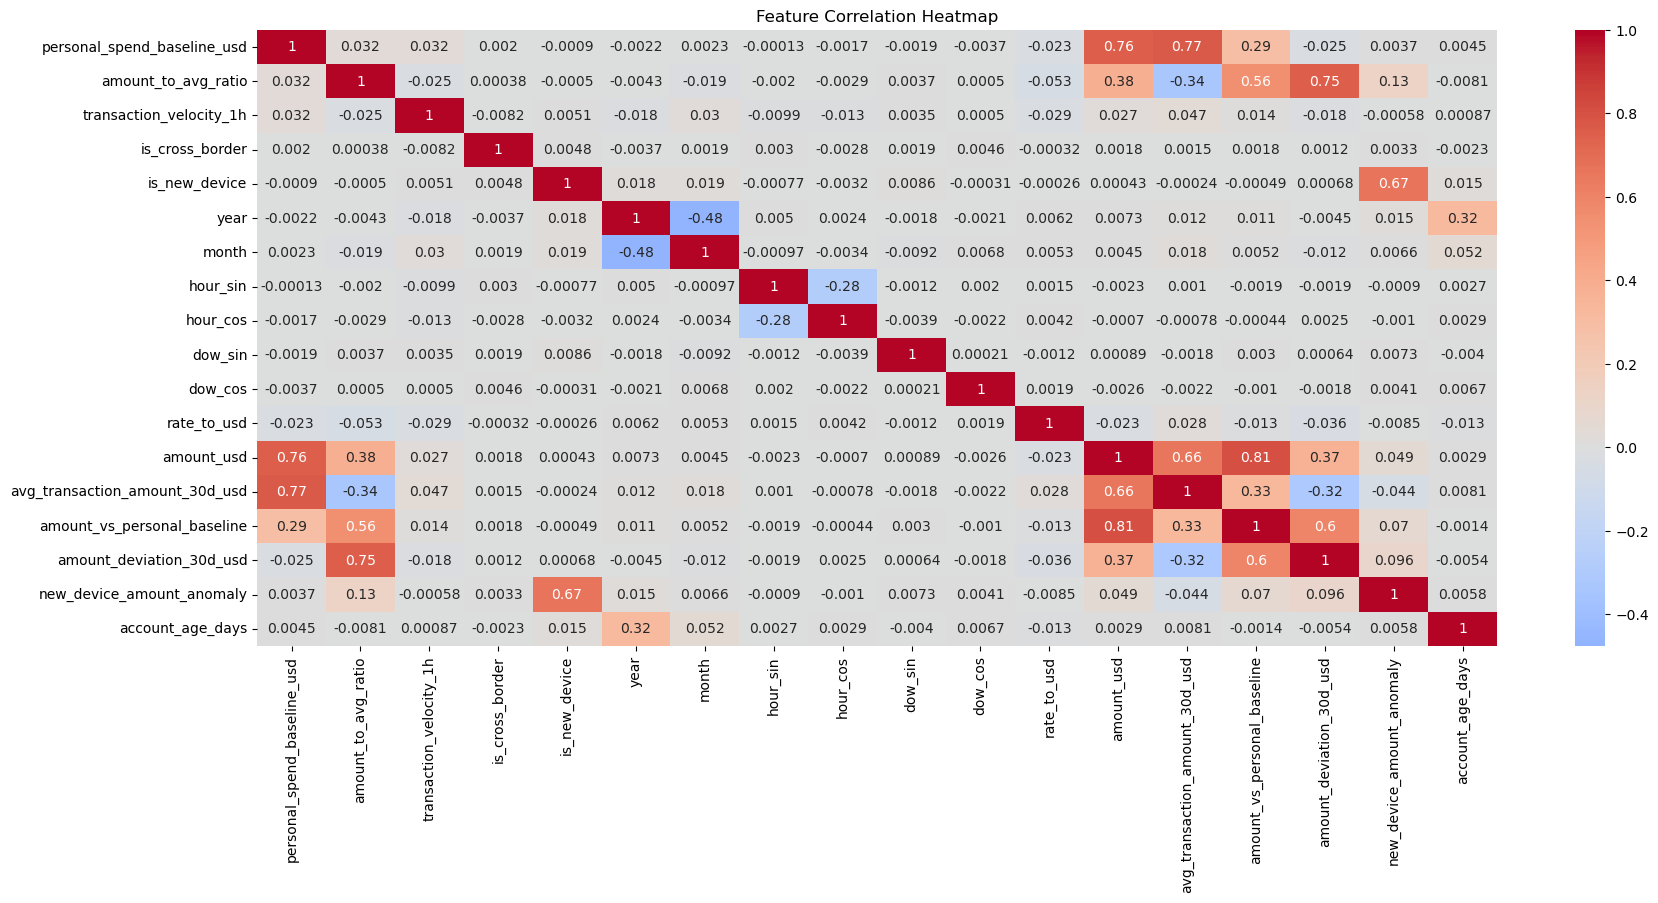

In [47]:
# Select only numeric columns
numeric_df = v_x_train.select_dtypes(include=[np.number])

# Compute correlation matrix
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(20,8))
sns.heatmap(corr_matrix, cmap="coolwarm", annot=True, center=0)
plt.title("Feature Correlation Heatmap")
plt.show()

In [48]:
v_x_reduced= v_x.drop(columns=[
    "personal_spend_baseline_usd",
    "amount_usd",
    "avg_transaction_amount_30d_usd",
    "year"
])

vif_data = pd.DataFrame()
vif_data["Feature"] = v_x_reduced.columns
vif_data["VIF"] = [variance_inflation_factor(v_x_reduced.values, i) 
                   for i in range(v_x_reduced.shape[1])]
vif_data.sort_values(by="VIF", ascending=False)


,Feature,VIF
0,amount_to_avg_ratio,3.802803
4,month,3.494352
10,amount_vs_personal_baseline,3.265189
13,account_age_days,3.222469
11,amount_deviation_30d_usd,2.095455
12,new_device_amount_anomaly,1.891285
3,is_new_device,1.890201
9,rate_to_usd,1.788302
6,hour_cos,1.293573
5,hour_sin,1.134307


##### Removal of features with high VIF reduced feature colinearity

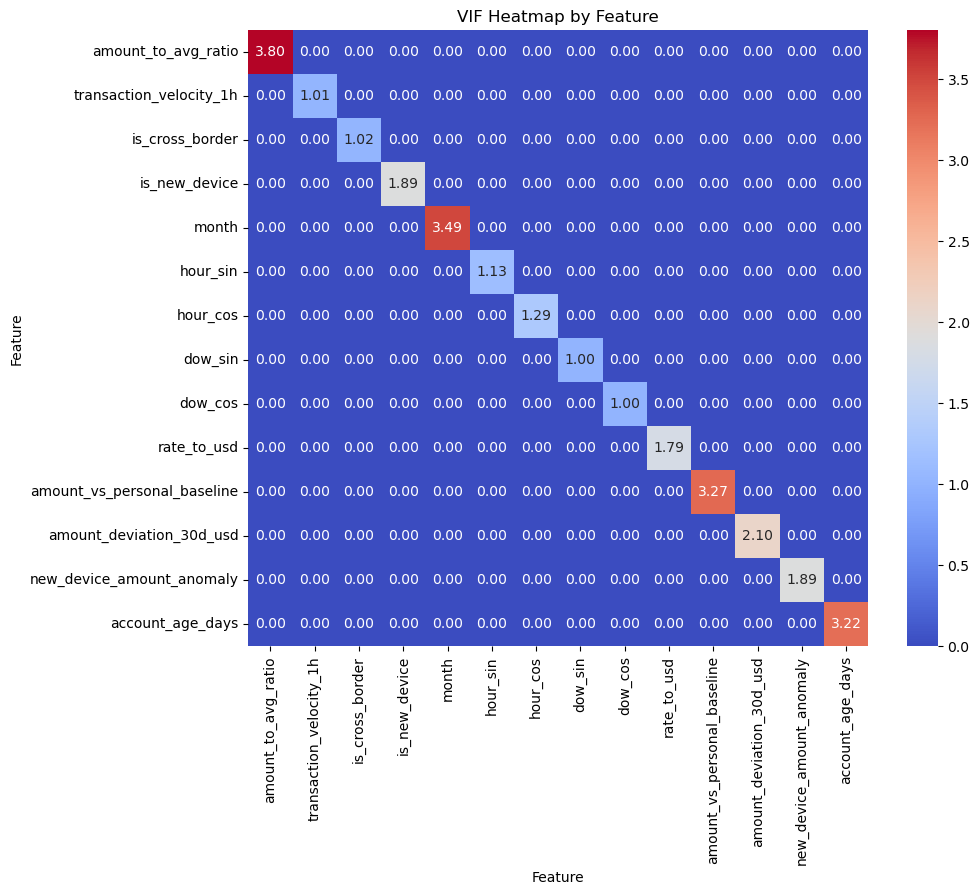

In [49]:
v_x = v_x_train.select_dtypes(include=[np.number])

v_x_reduced= v_x.drop(columns=[
    "personal_spend_baseline_usd",
    "amount_usd",
    "avg_transaction_amount_30d_usd",
    "year"
])


vif_data = pd.DataFrame()
vif_data["Feature"] = v_x_reduced.columns
vif_data["VIF"] = [variance_inflation_factor(v_x_reduced.values, i) 
                   for i in range(v_x_reduced.shape[1])]

# Create a pivot table for heatmap
vif_matrix = pd.DataFrame(
    np.diag(vif_data["VIF"].values), 
    index=vif_data["Feature"], 
    columns=vif_data["Feature"]
)

# Plot heatmap
plt.figure(figsize=(10,8))
sns.heatmap(vif_matrix, cmap="coolwarm", annot=True, fmt=".2f")
plt.title("VIF Heatmap by Feature")
plt.show()

In [50]:
# Removal of features with high VFI Score from log transformed data

df_log.drop(columns=['personal_spend_baseline_usd'],inplace=True)
df_log.drop(columns=['amount_usd'],inplace=True)
df_log.drop(columns=['avg_transaction_amount_30d_usd'],inplace=True)
df_log.drop(columns=['year'],inplace=True)



In [51]:
df_log.columns

Index(['account_type_y', 'kyc_tier_y', 'merchant_category', 'channel',
       'currency_y', 'amount_to_avg_ratio', 'transaction_velocity_1h',
       'transaction_country', 'home_country_y', 'is_cross_border',
       'is_new_device', 'is_fraud', 'month', 'hour_sin', 'hour_cos', 'dow_sin',
       'dow_cos', 'rate_to_usd', 'amount_vs_personal_baseline',
       'amount_deviation_30d_usd', 'new_device_amount_anomaly',
       'account_age_days'],
      dtype='object')

In [52]:
import os

# Define the folder path
folder_path = r"c:\Users\HP\OneDrive\Documents\AMDARI\FINLORA PROJECT\NOTEBOOK"

# Create the full save path for your new CSV file
save_path = os.path.join(folder_path, "log_transformed.csv")

# Save the dataframe to the folder (index=False stops it from adding an extra column of numbers)
df_log.to_csv(save_path, index=False)

print(f"File successfully saved to: {save_path}")

File successfully saved to: c:\Users\HP\OneDrive\Documents\AMDARI\FINLORA PROJECT\NOTEBOOK\log_transformed.csv
